# Gear dynamics 02: mesh stiffness and damping

Notebook 01 made the mesh a constraint $r_{b1}\theta_1 - r_{b2}\theta_2 = 0$. Real teeth bend,
flatten in the Hertzian contact and tilt in the gear body. Here the constraint becomes a
**spring-damper along the line of action**. One new coordinate appears, the
**dynamic transmission error**

$$\delta = r_{b1}\theta_1 - r_{b2}\theta_2 ,\qquad F = k\,\delta + c\,\dot\delta .$$

Constant stiffness, no backlash: the spring may even pull, which no tooth can do. Keep that
in mind and watch for negative forces. Notebook 04 fixes it.

**Contents:** where $k$ comes from (ISO 6336), the 2-DOF model and its two modes, the
equivalent mass, damping. Then four experiments:
**A** fix gear 2, preload gear 1, release · **B** release a twisted free pair ·
**C** sudden torque and the dynamic load factor · **D** read the damping back from a decay.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import geardyn as gd

gd.style()
gp = gd.GearPair()
print(gp.summary())

z1 / z2                                 24 / 48  -
ratio i = z2/z1                           2.000  -
module                                     2.50  mm
pressure angle                             20.0  deg
pitch radii r1 / r2               30.00 / 60.00  mm
base radii rb1 / rb2              28.19 / 56.38  mm
centre distance a                         90.00  mm
base pitch pb                             7.380  mm
contact ratio eps_alpha                   1.675  -
J1 / J2                   1.498e-04 / 2.397e-03  kg m^2
m1 / m2                           0.333 / 1.332  kg
equivalent mass m_eq                     0.1508  kg
mesh stiffness k (mean)                   316.3  N/um
mesh damping c                            690.6  N s/m
mesh natural frequency                     7288  Hz
backlash j_n                                  0  um


## 1  Where the mesh stiffness comes from

One loaded tooth pair deflects through three effects in series: tooth **bending and shear**
(a short cantilever), **Hertzian contact** flattening, and the **gear body** ("foundation")
rotating under the tooth root. ISO 6336-1 packs this into

* $c'$ = maximum stiffness of **one** tooth pair per mm face width, about **14 N/(mm·µm)** for
  solid steel spur gears (method B gives corrections for rim, profile shift and load);
* $c_{\gamma\alpha} = c'\,(0.75\,\varepsilon_\alpha + 0.25)$ = **mean mesh stiffness**,
  averaged over single and double contact.

$$k = c_{\gamma\alpha}\, b \qquad [\text{N/m along the LOA}]$$

A handy translation: referred to the pinion shaft, the mesh is a **torsional** spring
$k_\theta = k\,r_{b1}^2$.

In [2]:
T1 = 40.0
F0 = T1 / gp.rb1
d_shaft, L_shaft = 0.022, 0.10
k_shaft = 8.1e10 * np.pi * d_shaft**4 / 32 / L_shaft
print(f"c_gamma = {gp.c_gamma:.1f} N/(mm um)   ->  k = {gp.k_mesh/1e6:.0f} N/um")
print(f"static mesh deflection at {T1:.0f} N m : delta = F/k = {F0/gp.k_mesh*1e6:.2f} um "
      f"= {F0/gp.k_mesh/gp.rb1*1e6:.0f} urad at the pinion")
print(f"mesh as torsional spring at the pinion : k*rb1^2 = {gp.k_mesh*gp.rb1**2:.3e} N m/rad")
print(f"for scale, a 22 mm shaft, 100 mm long  : G*Jp/L   = {k_shaft:.3e} N m/rad "
      f"({gp.k_mesh*gp.rb1**2/k_shaft:.0f}x softer)")

c_gamma = 21.1 N/(mm um)   ->  k = 316 N/um
static mesh deflection at 40 N m : delta = F/k = 4.49 um = 159 urad at the pinion
mesh as torsional spring at the pinion : k*rb1^2 = 2.513e+05 N m/rad
for scale, a 22 mm shaft, 100 mm long  : G*Jp/L   = 1.863e+04 N m/rad (13x softer)


A few µm under full load, and the mesh is an order of magnitude stiffer than a typical
shaft. So the mesh rarely decides the *low* torsional modes of a drivetrain (shafts and big
inertias do, notebook 06). It dominates the **high-frequency** behaviour that teeth, bearings
and the housing (noise) feel.

## 2  The 2-DOF model

$$\begin{aligned}
J_1\ddot\theta_1 &= T_1 - r_{b1}F\\
J_2\ddot\theta_2 &= r_{b2}F - T_2
\end{aligned}\qquad
\mathbf M = \begin{bmatrix}J_1 & 0\\0 & J_2\end{bmatrix},\quad
\mathbf K = k\,\mathbf g\mathbf g^T,\quad \mathbf g = \begin{bmatrix}r_{b1}\\-r_{b2}\end{bmatrix}$$

$\mathbf K$ has rank 1, so there are **two modes**:

* **0 Hz, rigid-body rotation**: $\mathbf g^T\mathbf q = 0$, the rolling motion of notebook 01;
* the **mesh mode**: the gears swing against each other through the tooth spring.

Multiply the first equation by $r_{b1}/J_1$, the second by $r_{b2}/J_2$ and subtract. The
relative coordinate obeys a single-DOF equation

$$m_{eq}\ddot\delta + c\dot\delta + k\delta = m_{eq}\left(\frac{r_{b1}T_1}{J_1}+\frac{r_{b2}T_2}{J_2}\right),\qquad
  \frac{1}{m_{eq}} = \frac{r_{b1}^2}{J_1}+\frac{r_{b2}^2}{J_2}$$

with $f_n = \frac{1}{2\pi}\sqrt{k/m_{eq}}$. $J/r_b^2$ is the inertia "seen" along the LOA.
The two gears act like two masses in series, and the **lighter one dominates**. Damping is
defined through the ratio of this mode: $c = 2\zeta\sqrt{k\,m_{eq}}$.

In [3]:
m2 = gd.torsional_pair(gp, contact="linear")
f, V = m2.linear_modes()
print(f"modes of the 2-DOF model: {f[0]:.3g} Hz (rigid body), {f[1]:.1f} Hz (mesh)")
print(f"formula sqrt(k/m_eq)/2pi: {gp.f_n:.1f} Hz")
v = V[:, 1] * np.array([gp.rb1, gp.rb2])
print(f"mesh mode shape, motion along the LOA  r_b1*th1 : r_b2*th2 = 1 : {v[1]/v[0]:.3f}"
      f"  (= -m1'/m2' = {-(gp.J1/gp.rb1**2)/(gp.J2/gp.rb2**2):.3f})")

modes of the 2-DOF model: 0 Hz (rigid body), 7288.3 Hz (mesh)
formula sqrt(k/m_eq)/2pi: 7288.3 Hz
mesh mode shape, motion along the LOA  r_b1*th1 : r_b2*th2 = 1 : -0.250  (= -m1'/m2' = -0.250)


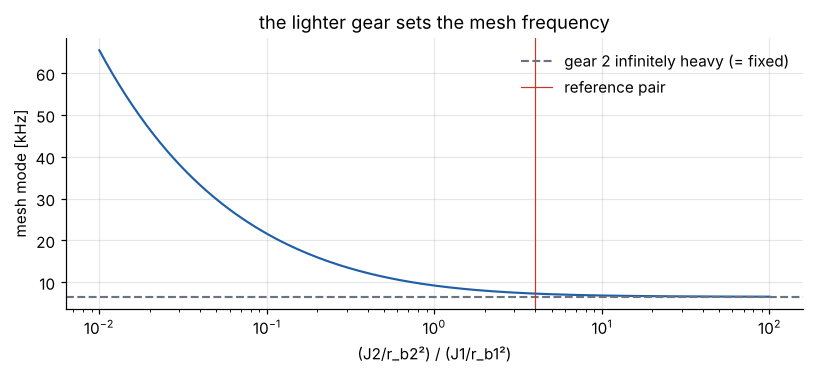

In [4]:
ratio = np.logspace(-2, 2, 200)            # (J2/rb2^2) / (J1/rb1^2)
m1p = gp.J1 / gp.rb1**2
meq = m1p * ratio * m1p / (m1p + ratio * m1p)
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.semilogx(ratio, np.sqrt(gp.k_mesh / meq) / 2 / np.pi / 1e3)
ax.axhline(np.sqrt(gp.k_mesh / m1p) / 2 / np.pi / 1e3, ls="--", color=gd.C["grey"],
           label="gear 2 infinitely heavy (= fixed)")
ax.axvline((gp.J2 / gp.rb2**2) / m1p, color=gd.C["red"], lw=0.8, label="reference pair")
ax.set_xlabel("(J2/r_b2²) / (J1/r_b1²)"); ax.set_ylabel("mesh mode [kHz]")
ax.set_title("the lighter gear sets the mesh frequency"); ax.legend()
plt.tight_layout()

## 3  Experiment A: fix gear 2, preload gear 1, release

Clamp gear 2 (`model.fix("th2")`), apply $T_1 = 40$ N m statically, then remove the torque
at $t=0$. Gear 1 is a torsional pendulum on the tooth spring,
$\omega = \sqrt{k r_{b1}^2/J_1}$. Energy bookkeeping (integrated alongside the states):

$$\underbrace{\tfrac12 J_1\dot\theta_1^2}_{T} + \underbrace{\tfrac12 k\delta^2}_{V}
  + \underbrace{\int c\dot\delta^2\,dt}_{E_\text{diss}} = \text{const} = V_0 = \frac{F_0^2}{2k}$$

measured frequency 6512 Hz, expected 6519 Hz (damped: 6512 Hz)
preload energy V0 = 3.18 mJ, max energy-balance error 2.1e-10 V0


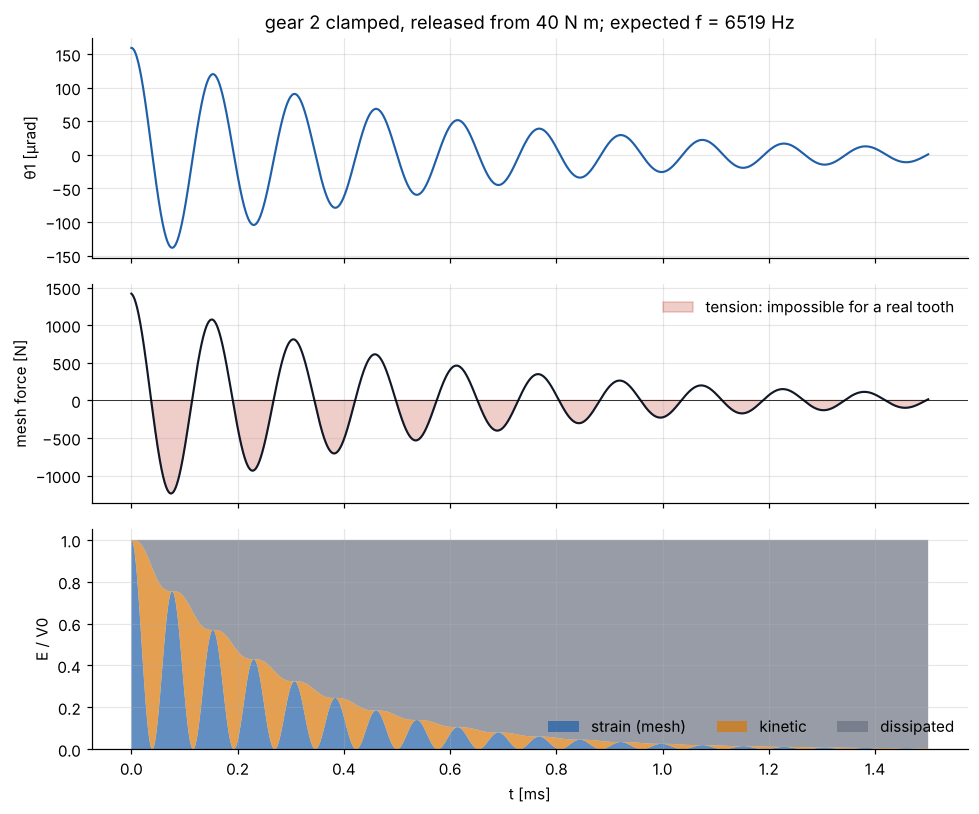

In [5]:
mA = gd.torsional_pair(gp, contact="linear")
mA.fix("th2")
Q = np.zeros(mA.n); Q[mA.index("th1")] = T1
q0 = mA.static(Q)
rA = mA.simulate(1.5e-3, q0=q0, n_out=3000)
FA = rA.mesh[0]["F"]
fA = np.sqrt(gp.k_mesh * gp.rb1**2 / gp.J1) / 2 / np.pi

fig, ax = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
tm = rA.t * 1e3
ax[0].plot(tm, rA["th1"] * 1e6); ax[0].set_ylabel("θ1 [µrad]")
ax[0].set_title(f"gear 2 clamped, released from {T1:.0f} N m; expected f = {fA:.0f} Hz")
ax[1].plot(tm, FA, color=gd.C["black"]); ax[1].axhline(0, color="k", lw=.5)
ax[1].fill_between(tm, FA, 0, where=FA < 0, color=gd.C["red"], alpha=0.25, label="tension: impossible for a real tooth")
ax[1].set_ylabel("mesh force [N]"); ax[1].legend(loc="upper right")
V0 = F0**2 / (2 * gp.k_mesh)
ax[2].stackplot(tm, rA.V / V0, rA.T / V0, rA.E_diss / V0,
                labels=["strain (mesh)", "kinetic", "dissipated"],
                colors=[gd.C["blue"], gd.C["orange"], gd.C["grey"]], alpha=0.7)
ax[2].set_ylabel("E / V0"); ax[2].set_xlabel("t [ms]"); ax[2].legend(loc="lower right", ncol=3)
plt.tight_layout()
pk = gd.peaks(rA["th1"])
print(f"measured frequency {1/np.mean(np.diff(rA.t[pk])):.0f} Hz, expected {fA:.0f} Hz "
      f"(damped: {fA*np.sqrt(1-(gp.zeta*np.sqrt(gp.m_eq/(gp.J1/gp.rb1**2)))**2):.0f} Hz)")
print(f"preload energy V0 = {V0*1e3:.2f} mJ, max energy-balance error {np.max(np.abs(rA.energy_residual))/V0:.1e} V0")

Strain energy and kinetic energy swap twice per period. The damper turns about $4\pi\zeta'$
of the energy into heat each cycle. Here $\zeta' = \zeta\sqrt{m_{eq}/m_1'}$ is a bit smaller
than the nominal 5 % because $c$ was defined for the *free* pair.

The red areas are the catch. Half the time the "tooth" pulls gear 1 back. With zero backlash
the coast flank would take over, so the result is right in that case, but only then. With any
clearance gear 1 flies freely. Notebook 04 repeats this experiment with backlash.

## 4  Experiment B: release a twisted free pair

Both gears are free now (no clamp, no torques). Start with the mesh compressed by the same
$\delta_0 = F_0/k$ and let go. Two conservation laws are worth checking:

* **Physical angular momentum** $H = J_1\omega_1 - J_2\omega_2$ (gear 2 turns CW) is **not**
  conserved. The bearings carry $\pm F$ on two different axes, and that couple changes $H$.
* What *is* conserved is the **momentum along the LOA**,
  $p = J_1\omega_1/r_{b1} + J_2\omega_2/r_{b2}$. Divide the two EOMs by their base radii and
  add them: $F$ cancels.

max |p| = 0.00e+00 (machine zero), max |H| = 2.43e-03 kg m^2/s
measured f = 7277 Hz


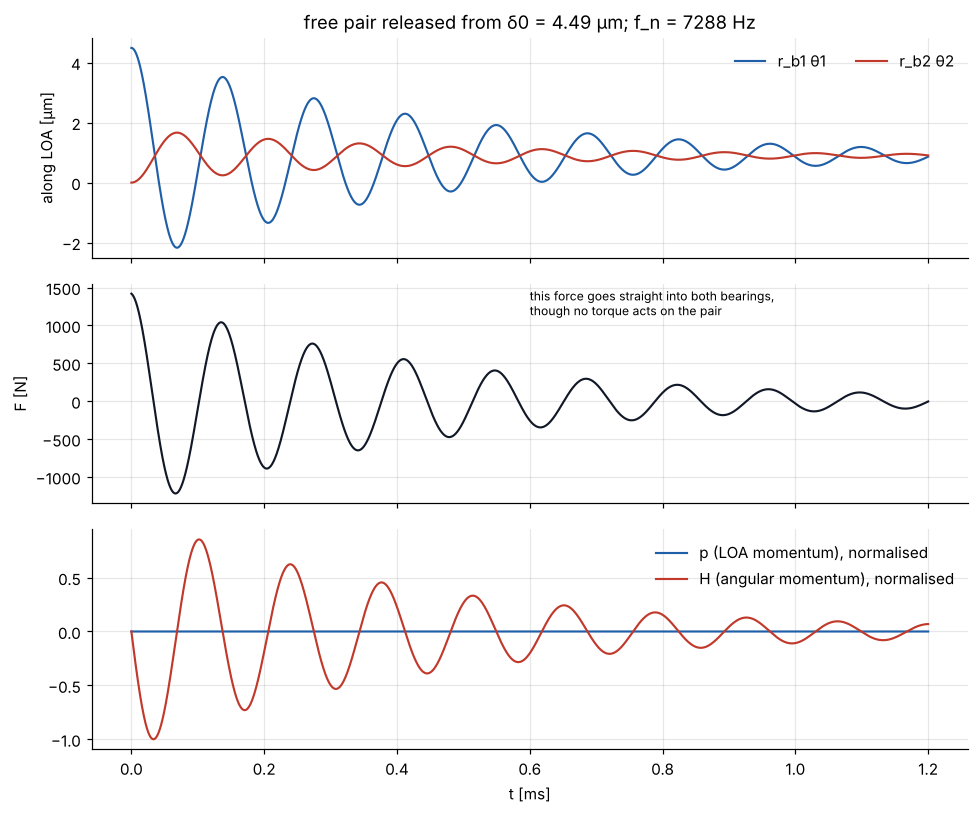

In [6]:
mB = gd.torsional_pair(gp, contact="linear")
d0 = F0 / gp.k_mesh
rB = mB.simulate(1.2e-3, q0=[d0 / gp.rb1, 0.0], n_out=3000)
w1, w2 = rB.vel("th1"), rB.vel("th2")
p = gp.J1 * w1 / gp.rb1 + gp.J2 * w2 / gp.rb2
H = gp.J1 * w1 - gp.J2 * w2
FB = rB.mesh[0]["F"]

fig, ax = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
tm = rB.t * 1e3
ax[0].plot(tm, gp.rb1 * rB["th1"] * 1e6, label="r_b1 θ1")
ax[0].plot(tm, gp.rb2 * rB["th2"] * 1e6, label="r_b2 θ2")
ax[0].set_ylabel("along LOA [µm]"); ax[0].legend(ncol=2)
ax[0].set_title(f"free pair released from δ0 = {d0*1e6:.2f} µm; f_n = {gp.f_n:.0f} Hz")
ax[1].plot(tm, FB, color=gd.C["black"]); ax[1].set_ylabel("F [N]")
ax[1].text(0.6, 0.8 * F0, "this force goes straight into both bearings,\nthough no torque acts on the pair", fontsize=8)
ax[2].plot(tm, p / np.abs(gp.J1 * w1 / gp.rb1).max(), label="p (LOA momentum), normalised")
ax[2].plot(tm, H / np.abs(H).max(), label="H (angular momentum), normalised")
ax[2].set_xlabel("t [ms]"); ax[2].legend()
plt.tight_layout()
print(f"max |p| = {np.abs(p).max():.2e} (machine zero), max |H| = {np.abs(H).max():.2e} kg m^2/s")
print(f"measured f = {1/np.mean(np.diff(rB.t[gd.peaks(rB['th1'])])):.0f} Hz")

The two gears oscillate in opposite directions, with amplitudes in the ratio of their LOA
masses. The pinion moves 4× more along the LOA than gear 2. The "internal" vibration
still loads the housing at mesh-mode frequency: a pure tooth-force oscillation is a
**dynamic bearing force** (notebook 05).

## 5  Experiment C: sudden torque and the dynamic load factor

Gear 2 now drives a big inertia ($J_{2,\text{extra}} = 0.05$ kg m²). Ramp $T_1$ from 0 to
40 N m linearly over a rise time $t_r$, with no damping. The rigid-model force
$F_\text{rigid}$ (notebook 01) is the "static" response. The spring adds an oscillation on
top. For a linear ramp into an undamped SDOF, structural dynamics gives the
**dynamic load factor**

$$\text{DLF} = \frac{F_\max}{F_\text{rigid}} = 1 + \frac{|\sin(\pi t_r/T_n)|}{\pi t_r/T_n}$$

which is 2 for a sudden step and falls towards 1 once the load is applied slowly compared
with the mesh period $T_n$.

F_rigid = 1403 N; step (t_r = 0.02 T_n): DLF = 1.999


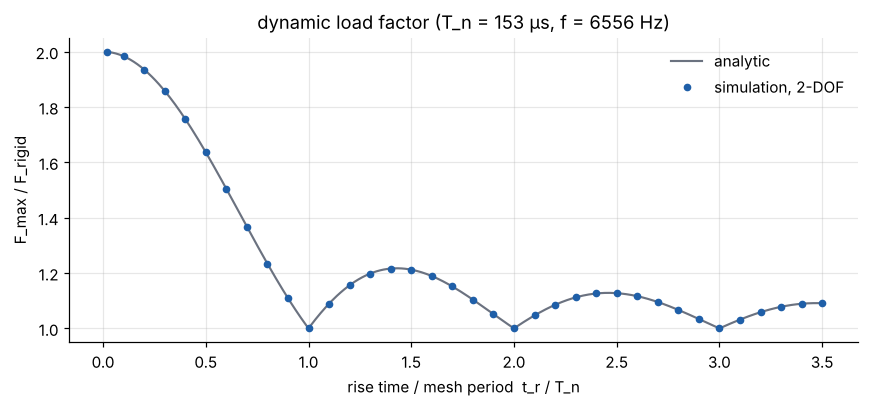

In [7]:
gC = gp.with_(J2_extra=0.05, zeta=0.0)
fC = gd.torsional_pair(gC).linear_modes()[0][1]
Tn = 1 / fC
_, _, F_rigid = gd.rigid_pair(gC, T1, 0.0)
taus = np.r_[0.02, np.linspace(0.1, 3.5, 35)]
dlf = []
for tau in taus:
    tr = tau * Tn
    mC = gd.torsional_pair(gC, contact="linear")
    mC.add_load("th1", lambda t, q, v, tr=tr: T1 * min(t / tr, 1.0))
    r = mC.simulate(tr + 3 * Tn, n_out=1500, max_step=Tn / 60)
    dlf.append(r.mesh[0]["F"].max() / F_rigid)
tt = np.linspace(0.01, 3.5, 400)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(tt, 1 + np.abs(np.sin(np.pi * tt)) / (np.pi * tt), color=gd.C["grey"], label="analytic")
ax.plot(taus, dlf, "o", color=gd.C["blue"], ms=4, label="simulation, 2-DOF")
ax.set_xlabel("rise time / mesh period  t_r / T_n"); ax.set_ylabel("F_max / F_rigid")
ax.set_title(f"dynamic load factor (T_n = {Tn*1e6:.0f} µs, f = {fC:.0f} Hz)"); ax.legend()
plt.tight_layout()
print(f"F_rigid = {F_rigid:.0f} N; step (t_r = 0.02 T_n): DLF = {dlf[0]:.3f}")

The mesh period is about 0.15 ms. Almost every *real* torque change (combustion, clutch
engagement) is slow by that standard, so the mesh responds quasi-statically. The exceptions
are impacts: backlash crossings, a gear tooth hitting a dog, a chain slap. Those rise within
microseconds and can double the tooth force. The steady-state excitation at mesh
frequency comes from the teeth themselves (notebook 03).

## 6  Experiment D: read the damping back from a decay

Mesh damping is the most uncertain parameter in gear dynamics. Measured values range from
$\zeta \approx 0.02$ to $0.17$, depending on lubrication, load and speed. The usual way to
identify it is a ring-down, as in experiment A, followed by the **logarithmic decrement**

$$\Lambda = \frac1N\ln\frac{x_0}{x_N},\qquad \zeta = \frac{\Lambda}{\sqrt{4\pi^2+\Lambda^2}} .$$

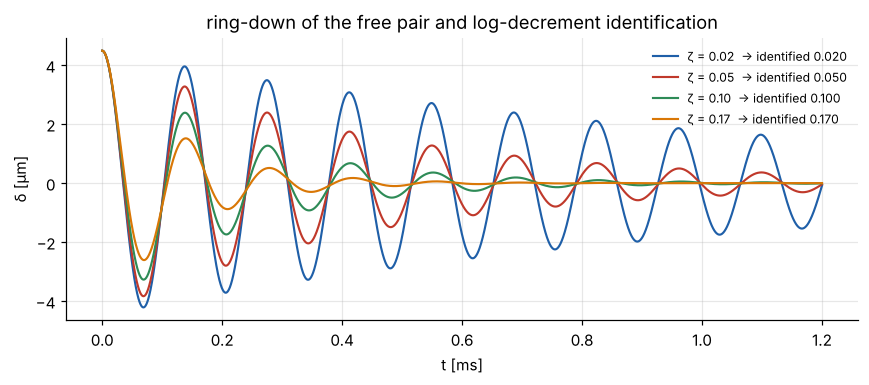

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for z in [0.02, 0.05, 0.10, 0.17]:
    g = gp.with_(zeta=z)
    m = gd.torsional_pair(g, contact="linear")
    r = m.simulate(1.2e-3, q0=[d0 / g.rb1, 0.0], n_out=4000)
    dlt = g.rb1 * r["th1"] - g.rb2 * r["th2"]
    pk = gd.peaks(dlt)
    N = min(4, len(pk) - 1)
    Lam = np.log(dlt[pk[0]] / dlt[pk[N]]) / N
    z_est = Lam / np.sqrt(4 * np.pi**2 + Lam**2)
    ax.plot(r.t * 1e3, dlt * 1e6, label=f"ζ = {z:.2f}  -> identified {z_est:.3f}")
ax.set_xlabel("t [ms]"); ax.set_ylabel("δ [µm]"); ax.legend(fontsize=8)
ax.set_title("ring-down of the free pair and log-decrement identification")
plt.tight_layout()

## 7  Take-aways

* Mesh = spring-damper on the LOA, $F = k\delta + c\dot\delta$, with $k \approx c_{\gamma\alpha} b$
  (about 20 N/(mm·µm) times face width). A few µm deflection under full load.
* The pair has a rigid-body mode and **one mesh mode** governed by
  $m_{eq} = (r_{b1}^2/J_1 + r_{b2}^2/J_2)^{-1}$. The lighter gear sets the frequency.
* Momentum *along the LOA* is conserved, angular momentum is not. Internal mesh vibration
  always loads the bearings.
* Quasi-static unless the load changes within about one mesh period. Then the dynamic load
  factor approaches 2.
* A bilateral spring pulls: valid **only** for zero backlash. Next stop: the stiffness is not
  constant either (03).

## Exercises

1. Experiment A with $\zeta = 0$: confirm that the energy residual stays at integrator noise.
   Then tighten `rtol` and see it drop.
2. Make the pinion part of a crankshaft: `J1_extra = 0.01`. How far does the mesh mode drop,
   and which gear dominates it now?
3. Experiment C with a **half-cosine** ramp instead of a linear one. Is the DLF curve
   smoother? Why? (Look at the jerk at the start and end of the ramp.)
4. Derive the 1-DOF equation for $\delta$ in sympy from the two EOMs and confirm the
   right-hand side for $T_2 = i\,T_1$ equals $T_1/r_{b1}$.